In [ ]:

import os
import zipfile
import urllib.request

# Download official hydraulic dataset
url = "https://zenodo.org/records/1323611/files/data.zip?download=1"
zip_path = "/content/hydraulic_data.zip"
extract_path = "/content/hydraulic_data"

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_path)

print("Extracting dataset...")

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Download and extraction complete!")


Extracting dataset...
Download and extraction complete!


In [ ]:

import os

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(os.path.join(root, file))


/content/hydraulic_data/VS1.txt
/content/hydraulic_data/TS4.txt
/content/hydraulic_data/PS3.txt
/content/hydraulic_data/PS2.txt
/content/hydraulic_data/documentation.txt
/content/hydraulic_data/PS4.txt
/content/hydraulic_data/TS1.txt
/content/hydraulic_data/SE.txt
/content/hydraulic_data/PS1.txt
/content/hydraulic_data/CP.txt
/content/hydraulic_data/FS1.txt
/content/hydraulic_data/TS3.txt
/content/hydraulic_data/PS5.txt
/content/hydraulic_data/TS2.txt
/content/hydraulic_data/CE.txt
/content/hydraulic_data/description.txt
/content/hydraulic_data/EPS1.txt
/content/hydraulic_data/PS6.txt
/content/hydraulic_data/FS2.txt
/content/hydraulic_data/profile.txt


In [ ]:

import os
import glob
import numpy as np
import pandas as pd

# Find the extracted dataset files
all_files = glob.glob(
    os.path.join(extract_path, "**", "*.txt"),
    recursive=True
)

def find_file(filename):
    matches = [
        f for f in all_files
        if os.path.basename(f).lower() == filename.lower()
    ]
    if not matches:
        raise FileNotFoundError(f"{filename} not found")
    return matches[0]

# Load cycle-level condition information
profile = pd.read_csv(
    find_file("profile.txt"),
    sep="\t",
    header=None
)

# Column 3 = internal pump leakage
# Column 5 = stability flag
pump_labels = profile.iloc[:, 2].astype(int)
stability = profile.iloc[:, 4].astype(int)

print("Profile shape:", profile.shape)
print("\nPump leakage distribution:")
print(pump_labels.value_counts().sort_index())

print("\nStability distribution:")
print(stability.value_counts().sort_index())


Profile shape: (2205, 5)

Pump leakage distribution:
2
0    1221
1     492
2     492
Name: count, dtype: int64

Stability distribution:
4
0    1449
1     756
Name: count, dtype: int64


In [ ]:

sensor_names = [
    "PS1", "PS2", "PS3", "PS4", "PS5", "PS6",
    "FS1", "FS2", "EPS1"
]

features = pd.DataFrame(index=range(len(profile)))

for sensor in sensor_names:

    print("Processing:", sensor)

    data = pd.read_csv(
        find_file(sensor + ".txt"),
        sep="\t",
        header=None
    ).to_numpy(dtype=np.float32)

    # Verify one row per operating cycle
    assert data.shape[0] == len(profile), (
        f"Cycle mismatch in {sensor}: {data.shape}"
    )

    features[sensor + "_mean"] = np.mean(data, axis=1)
    features[sensor + "_std"] = np.std(data, axis=1)
    features[sensor + "_min"] = np.min(data, axis=1)
    features[sensor + "_max"] = np.max(data, axis=1)
    features[sensor + "_rms"] = np.sqrt(
        np.mean(data ** 2, axis=1)
    )
    features[sensor + "_ptp"] = np.ptp(data, axis=1)

    del data

print("\nFeature extraction complete!")
print("Feature table shape:", features.shape)
display(features.head())


Processing: PS1
Processing: PS2
Processing: PS3
Processing: PS4
Processing: PS5
Processing: PS6
Processing: FS1
Processing: FS2
Processing: EPS1

Feature extraction complete!
Feature table shape: (2205, 54)


,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_rms,PS1_ptp,PS2_mean,PS2_std,PS2_min,PS2_max,...,FS2_min,FS2_max,FS2_rms,FS2_ptp,EPS1_mean,EPS1_std,EPS1_min,EPS1_max,EPS1_rms,EPS1_ptp
0,160.673752,13.938125,145.830002,191.509995,161.277466,45.679993,109.466820,47.110435,0.0,156.990005,...,10.148,10.446,10.305004,0.298,2538.977783,185.598877,2339.800049,2951.600098,2545.728271,611.800049
1,160.602661,14.117697,145.729996,191.470001,161.222321,45.740005,109.354851,47.041576,0.0,157.559998,...,10.352,10.453,10.403120,0.101,2531.571777,189.923615,2332.000000,2947.399902,2538.629150,615.399902
2,160.347488,14.191456,145.369995,191.410004,160.975037,46.040009,109.158760,46.988239,0.0,156.970001,...,10.296,10.443,10.366284,0.147,2519.982666,190.721130,2318.600098,2939.800049,2527.135742,621.199951
3,160.188141,14.226619,145.139999,191.339996,160.818939,46.199997,109.064812,46.968227,0.0,156.440002,...,10.241,10.382,10.302712,0.141,2511.614258,191.256210,2310.800049,2929.600098,2518.801025,618.800049
4,159.999527,14.275260,144.949997,191.410004,160.635986,46.460007,108.931580,46.870827,0.0,158.130005,...,10.179,10.312,10.237790,0.133,2503.528564,191.242828,2301.800049,2923.800049,2510.747070,622.000000


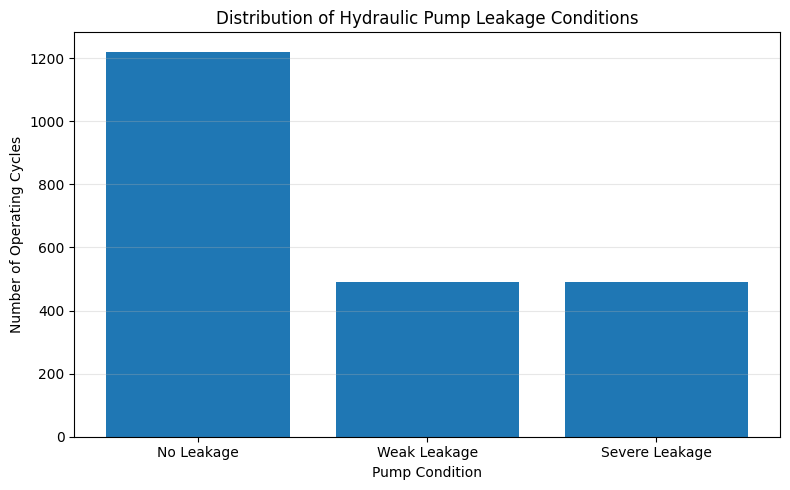

2
0    1221
1     492
2     492
Name: count, dtype: int64


In [ ]:

import matplotlib.pyplot as plt

class_counts = pump_labels.value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    ["No Leakage", "Weak Leakage", "Severe Leakage"],
    class_counts.values
)

plt.title("Distribution of Hydraulic Pump Leakage Conditions")
plt.xlabel("Pump Condition")
plt.ylabel("Number of Operating Cycles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(class_counts)


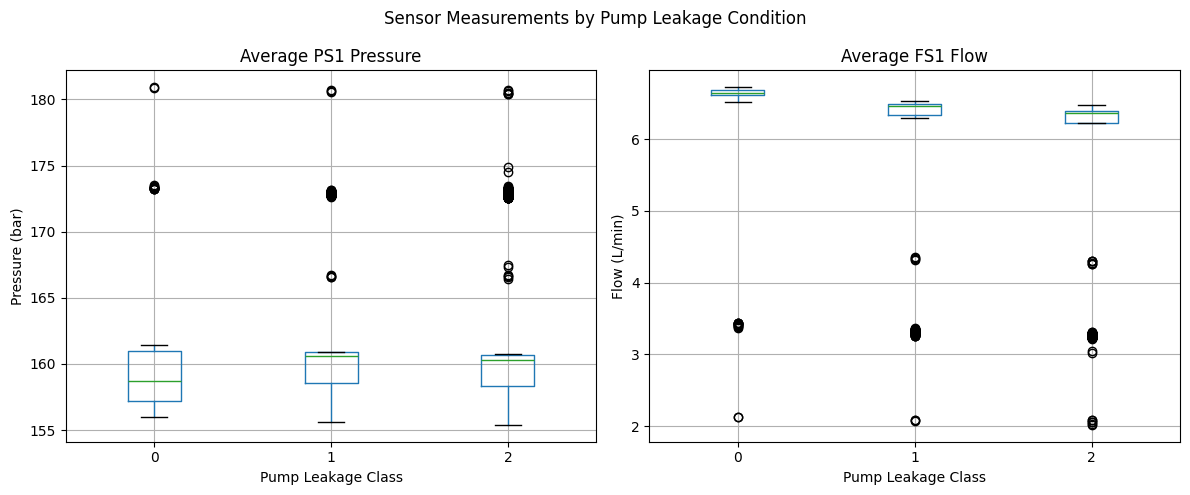

In [ ]:

plot_data = features.copy()
plot_data["Pump Condition"] = pump_labels.values

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_data.boxplot(
    column="PS1_mean",
    by="Pump Condition",
    ax=axes[0]
)
axes[0].set_title("Average PS1 Pressure")
axes[0].set_xlabel("Pump Leakage Class")
axes[0].set_ylabel("Pressure (bar)")

plot_data.boxplot(
    column="FS1_mean",
    by="Pump Condition",
    ax=axes[1]
)
axes[1].set_title("Average FS1 Flow")
axes[1].set_xlabel("Pump Leakage Class")
axes[1].set_ylabel("Flow (L/min)")

plt.suptitle("Sensor Measurements by Pump Leakage Condition")
plt.tight_layout()
plt.show()


In [ ]:

# Keep only stable operating cycles
stable_mask = stability == 0

X_stable = features.loc[stable_mask].reset_index(drop=True)
y_stable = pump_labels.loc[stable_mask].reset_index(drop=True)

print("Stable dataset shape:", X_stable.shape)

print("\nPump leakage distribution in stable cycles:")
print(y_stable.value_counts().sort_index())

print("\nPercentages:")
print(
    (y_stable.value_counts(normalize=True).sort_index() * 100)
    .round(2)
)


Stable dataset shape: (1449, 54)

Pump leakage distribution in stable cycles:
2
0    489
1    480
2    480
Name: count, dtype: int64

Percentages:
2
0    33.75
1    33.13
2    33.13
Name: proportion, dtype: float64


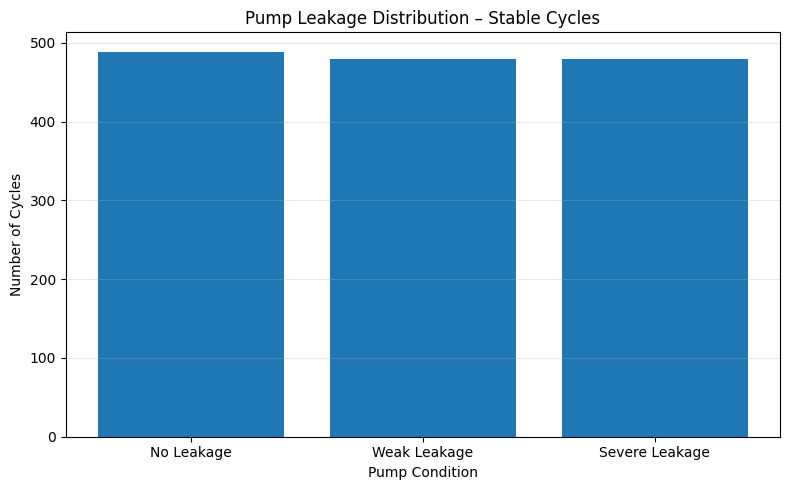

In [ ]:

import matplotlib.pyplot as plt

stable_counts = y_stable.value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(
    ["No Leakage", "Weak Leakage", "Severe Leakage"],
    stable_counts.values
)

plt.title("Pump Leakage Distribution – Stable Cycles")
plt.xlabel("Pump Condition")
plt.ylabel("Number of Cycles")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


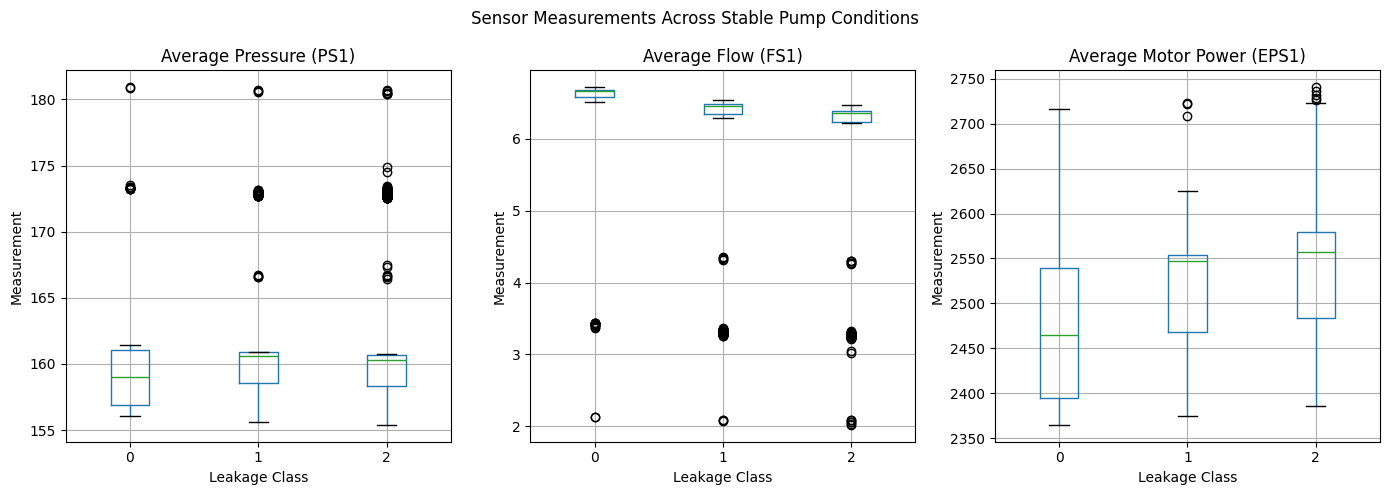

In [ ]:

stable_plot = X_stable.copy()
stable_plot["Pump Condition"] = y_stable

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

sensor_features = [
    ("PS1_mean", "Average Pressure (PS1)"),
    ("FS1_mean", "Average Flow (FS1)"),
    ("EPS1_mean", "Average Motor Power (EPS1)")
]

for ax, (column, title) in zip(axes, sensor_features):
    stable_plot.boxplot(
        column=column,
        by="Pump Condition",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Leakage Class")
    ax.set_ylabel("Measurement")

plt.suptitle("Sensor Measurements Across Stable Pump Conditions")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import matplotlib.pyplot as plt

# Prepare inputs and target
X = X_stable.copy()
y = y_stable.copy()

# 60% training, 20% validation, 20% testing
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Testing:", X_test.shape)

# Model 1: Logistic Regression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

logistic_model.fit(X_train, y_train)

# Model 2: Random Forest
forest_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

forest_model.fit(X_train, y_train)

# Validation predictions
logistic_predictions = logistic_model.predict(X_validation)
forest_predictions = forest_model.predict(X_validation)

# Compare models
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_validation, logistic_predictions),
        accuracy_score(y_validation, forest_predictions)
    ],
    "Macro F1": [
        f1_score(y_validation, logistic_predictions, average="macro"),
        f1_score(y_validation, forest_predictions, average="macro")
    ]
})

display(results)


Training: (869, 54)
Validation: (290, 54)
Testing: (290, 54)


,Model,Accuracy,Macro F1
0,Logistic Regression,0.982759,0.982638
1,Random Forest,0.982759,0.982627


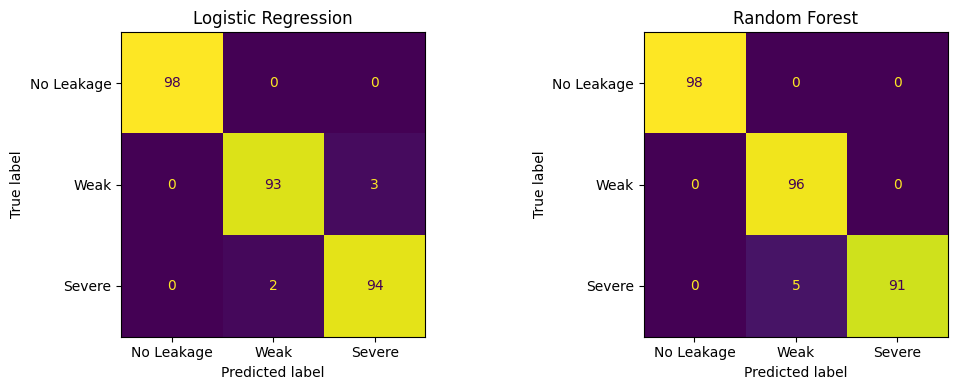

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, predictions, model_name in zip(
    axes,
    [logistic_predictions, forest_predictions],
    ["Logistic Regression", "Random Forest"]
):
    cm = confusion_matrix(
        y_validation,
        predictions,
        labels=[0, 1, 2]
    )

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Leakage", "Weak", "Severe"]
    )

    display_matrix.plot(ax=ax, colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()


In [ ]:

# Final test predictions
logistic_test_predictions = logistic_model.predict(X_test)
forest_test_predictions = forest_model.predict(X_test)

# Compare test performance
test_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, logistic_test_predictions),
        accuracy_score(y_test, forest_test_predictions)
    ],
    "Macro F1": [
        f1_score(y_test, logistic_test_predictions, average="macro"),
        f1_score(y_test, forest_test_predictions, average="macro")
    ]
})

display(test_results)

# Detailed classification report
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
    logistic_test_predictions,
    target_names=["No Leakage", "Weak Leakage", "Severe Leakage"]
))

print("RANDOM FOREST")
print(classification_report(
    y_test,
    forest_test_predictions,
    target_names=["No Leakage", "Weak Leakage", "Severe Leakage"]
))


,Model,Accuracy,Macro F1
0,Logistic Regression,0.989655,0.989672
1,Random Forest,0.993103,0.993055


LOGISTIC REGRESSION
                precision    recall  f1-score   support

    No Leakage       0.99      0.99      0.99        98
  Weak Leakage       0.98      0.99      0.98        96
Severe Leakage       1.00      0.99      0.99        96

      accuracy                           0.99       290
     macro avg       0.99      0.99      0.99       290
  weighted avg       0.99      0.99      0.99       290

RANDOM FOREST
                precision    recall  f1-score   support

    No Leakage       1.00      1.00      1.00        98
  Weak Leakage       0.98      1.00      0.99        96
Severe Leakage       1.00      0.98      0.99        96

      accuracy                           0.99       290
     macro avg       0.99      0.99      0.99       290
  weighted avg       0.99      0.99      0.99       290



Top 10 important features:


,Importance
FS1_mean,0.184726
FS1_rms,0.166772
FS1_std,0.057502
EPS1_rms,0.056820
EPS1_mean,0.054095
EPS1_max,0.052189
PS3_rms,0.042099
PS3_mean,0.041678
EPS1_min,0.039486
PS1_max,0.036611


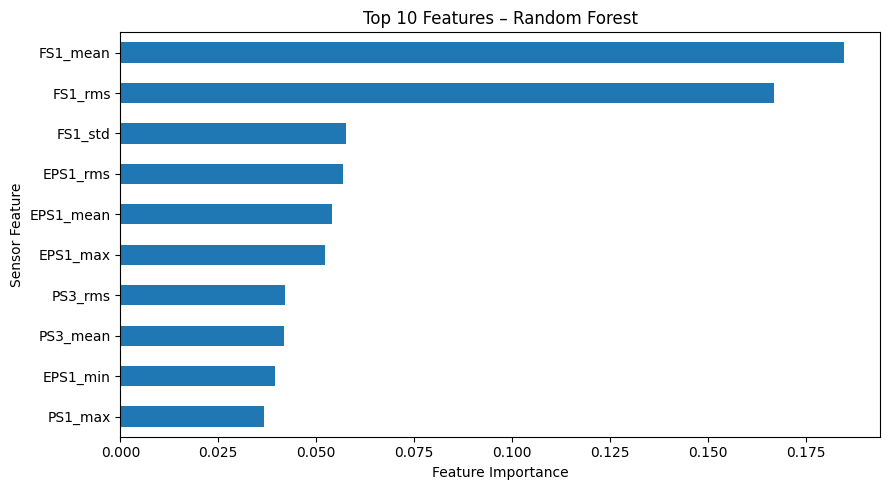

In [ ]:

importance = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 important features:")
display(importance.head(10).to_frame("Importance"))

plt.figure(figsize=(9, 5))
importance.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Features – Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Sensor Feature")
plt.tight_layout()
plt.show()
